# Notebook 3 — Analisis Karakteristik Temporal dan Spasial Chlorophyll-a di Perairan NTT

**Proyek:** Analisis Spatiotemporal Marine Heatwaves (MHW), Klorofil-a, dan Konteks Perikanan Tangkap Provinsi Nusa Tenggara Timur  
**Dokumen Rujukan Metodologis:** `REVISI_PBL.md`

---

## 1. Landasan Metodologis dan Integritas Data Klorofil-a

1. **Resolusi dan Sensor Satelit:**
   - Menggunakan dataset ESA CCI Ocean Colour v6.0 / MODIS-Aqua daily merged product (~4 km, 0.0416°).
   - Observasi operasional kontinu multi-sensor tersedia mulai Juli 2002 hingga Desember 2020.
2. **Preservasi Nilai Hilang (Zero-Filling Prevention):**
   - Area perairan yang tertutup awan monsun (terutama pada periode Monsun Barat / DJF) dipertahankan sebagai `NaN`.
   - **Ketentuan Mutlak:** Tidak ada pengisian sintetis nilai nol (`0.0`) pada sel grid tanpa data, karena nilai nol akan mengacaukan rata-rata biologis dan memberikan ilusi anomali negatif ekstrem palsu.
3. **Penyelarasan Spasial (Regridding Strategy):**
   - Data resolusi ~4 km diselaraskan dengan grid 0.25° OISST melalui pendekatan *conservative block-averaging* di Notebook 4 untuk menjaga konservasi fluks massa pigmen fitoplankton.
4. **Dokumentasi Tutupan Observasi (Pixel Coverage Ratio):**
   - Setiap analisis deret waktu dan komposit spasial wajib melaporkan persentase piksel laut yang memiliki data valid (*valid observation percentage*).


---
## 1. Konfigurasi dan Impor Pustaka

In [1]:
import sys
import os
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
import matplotlib.colors as mcolors

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

notebook_dir = Path(os.path.abspath(''))
project_root = notebook_dir.parent if notebook_dir.name == 'notebooks' else notebook_dir
sys.path.insert(0, str(project_root))
sys.path.insert(0, str(project_root / 'config'))

import project_config as cfg

print("=" * 60)
print("KONFIGURASI NOTEBOOK 3 — ANALISIS CHLOROPHYLL-A")
print("=" * 60)
print(f"Project Root     : {cfg.PROJECT_ROOT}")
print(f"Input Chl-a      : {cfg.CHLA_MERGED_OUTPUT}")
print(f"Folder Output    : {cfg.PROCESSED_DIR}")

KONFIGURASI NOTEBOOK 3 — ANALISIS CHLOROPHYLL-A
Project Root     : G:\My Drive\KLIMTROP\PBL
Input Chl-a      : G:\My Drive\KLIMTROP\PBL\data\processed\chlorophyll_a_daily_ntt.nc
Folder Output    : G:\My Drive\KLIMTROP\PBL\data\processed


---
## 2. Pemuatan dan Verifikasi Dataset Chlorophyll-a Gabungan

In [2]:
chla_file = cfg.CHLA_MERGED_OUTPUT

if not chla_file.exists():
    raise FileNotFoundError(
        f"File chlorophyll-a gabungan tidak ditemukan di: {chla_file}\n"
        "Jalankan Notebook 1 terlebih dahulu untuk menghasilkan dataset ini."
    )

ds_chla = xr.open_dataset(chla_file)
print("Dataset Chlorophyll-a berhasil dimuat:")
print(f"  Dimensi: {dict(ds_chla.sizes)}")
print(f"  Variabel: {list(ds_chla.data_vars)}")
print(f"  Rentang Waktu: {str(ds_chla.time.values[0])[:10]} s.d. {str(ds_chla.time.values[-1])[:10]} ({len(ds_chla.time)} hari)")
print(f"  Grid Spasial: {len(ds_chla.lat)} lat x {len(ds_chla.lon)} lon (~4 km)")
print(f"  Resolusi Lat : {abs(float(ds_chla.lat[1] - ds_chla.lat[0])):.4f}°")
print(f"  Resolusi Lon : {abs(float(ds_chla.lon[1] - ds_chla.lon[0])):.4f}°")
print(f"  Lat range: {float(ds_chla.lat.min()):.3f}° s.d. {float(ds_chla.lat.max()):.3f}°")
print(f"  Lon range: {float(ds_chla.lon.min()):.3f}° s.d. {float(ds_chla.lon.max()):.3f}°")

Dataset Chlorophyll-a berhasil dimuat:
  Dimensi: {'time': 7669, 'lat': 144, 'lon': 240}
  Variabel: ['chlor_a', 'total_nobs']
  Rentang Waktu: 2000-01-01 s.d. 2020-12-31 (7669 hari)
  Grid Spasial: 144 lat x 240 lon (~4 km)


  Resolusi Lat : 0.0417°
  Resolusi Lon : 0.0417°
  Lat range: -12.979° s.d. -7.021°
  Lon range: 117.521° s.d. 127.479°


---
## 3. Analisis Kualitas Data dan Proporsi Tutupan Awan (Data Gaps)

Sensor optik satelit (*Ocean Colour*) tidak dapat menembus awan tebal. Di perairan tropis Indonesia, tutupan awan bervariasi secara musiman (tinggi pada Monsun Barat, lebih rendah pada Monsun Timur).  
**Prinsip PRD:** Nilai hilang dipertahankan sebagai NaN untuk mencegah distorsi estimasi rata-rata.

Menganalisis proporsi data valid secara temporal...



Kualitas Data Chlorophyll-a per Tahun:
      pct_valid_mean  pct_valid_median  hari_observasi
year                                                  
2000           16.23             10.74             365
2001           18.57             13.31             364
2002           36.14             37.87             365
2003           44.03             48.95             365
2004           44.19             47.56             366
2005           41.29             43.31             365
2006           41.04             43.40             365
2007           38.56             38.00             365
2008           38.44             40.24             366
2009           38.12             39.39             365
2010           32.93             32.27             365
2011           31.86             30.56             365
2012           35.23             34.08             366
2013           30.64             29.54             365
2014           35.21             34.94             365
2015           39.38     

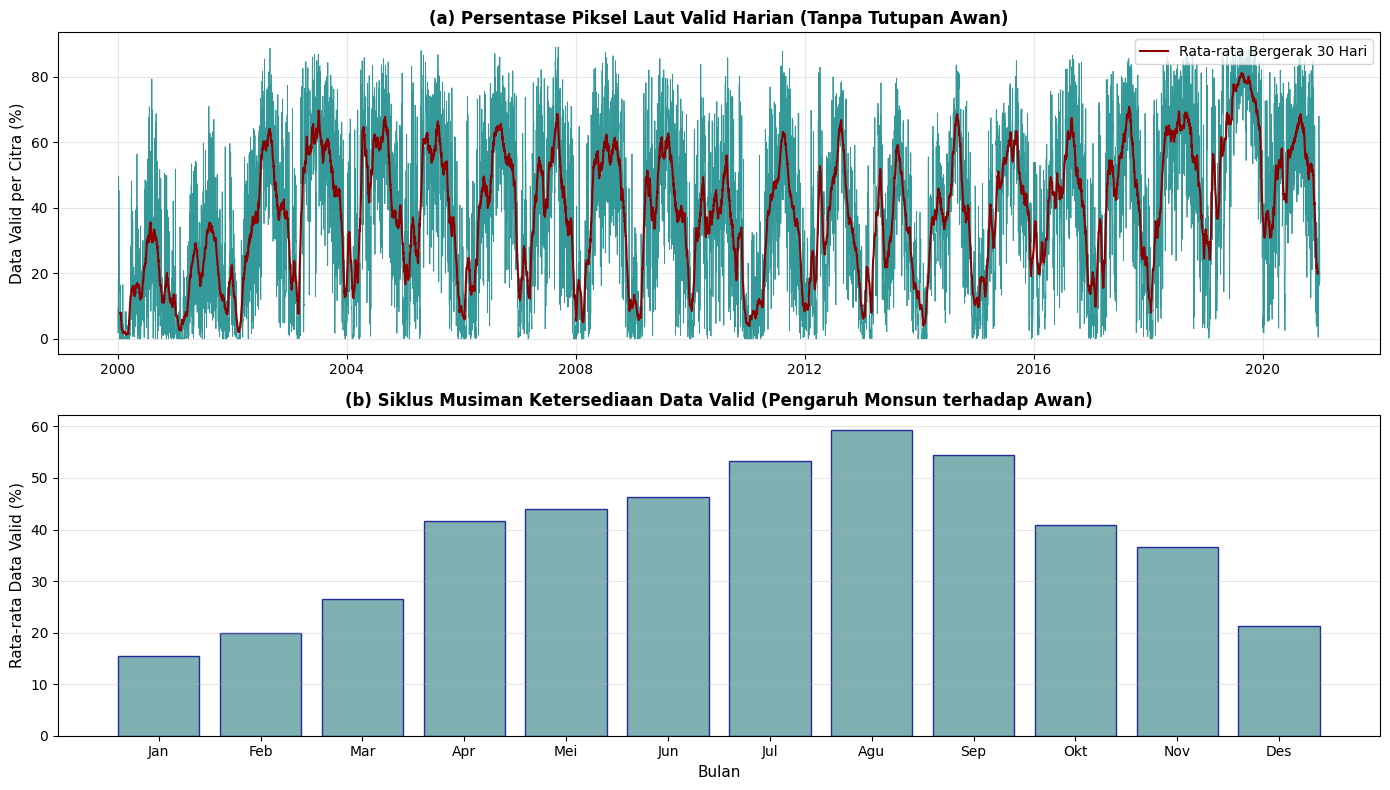

In [3]:
# Evaluasi data valid per langkah waktu
print("Menganalisis proporsi data valid secara temporal...")

valid_counts_time = (~np.isnan(ds_chla['chlor_a'])).sum(dim=['lat', 'lon']).values
total_pixels_grid = len(ds_chla.lat) * len(ds_chla.lon)
pct_valid_time = 100.0 * valid_counts_time / total_pixels_grid

df_quality_ts = pd.DataFrame({
    'time': pd.to_datetime(ds_chla.time.values),
    'valid_pixels': valid_counts_time,
    'pct_valid': pct_valid_time,
    'pct_missing': 100.0 - pct_valid_time
}).set_index('time')

df_quality_ts['year'] = df_quality_ts.index.year
df_quality_ts['month'] = df_quality_ts.index.month

# Ringkasan per tahun
annual_quality = df_quality_ts.groupby('year').agg(
    pct_valid_mean=('pct_valid', 'mean'),
    pct_valid_median=('pct_valid', 'median'),
    hari_observasi=('pct_valid', 'count')
).round(2)

print("\nKualitas Data Chlorophyll-a per Tahun:")
print(annual_quality)

# Ringkasan per bulan (variasi musiman tutupan awan)
monthly_quality = df_quality_ts.groupby('month').agg(
    pct_valid_mean=('pct_valid', 'mean'),
    pct_missing_mean=('pct_missing', 'mean')
).round(2)
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
monthly_quality.index = month_names
print("\nProporsi Rata-rata Tutupan Awan (Missing Data) per Bulan (%):")
print(monthly_quality)

# Simpan laporan kualitas data ke CSV
df_quality_ts.to_csv(cfg.CHLA_QUALITY_OUTPUT)
print(f"\n✅ Laporan kualitas data disimpan: {cfg.CHLA_QUALITY_OUTPUT}")

# Visualisasi Proporsi Data Valid
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Panel 1: Deret Waktu Kelengkapan Data Harian
axes[0].plot(df_quality_ts.index, df_quality_ts['pct_valid'], color='teal', lw=0.6, alpha=0.8)
axes[0].plot(df_quality_ts['pct_valid'].rolling(30, center=True).mean(), color='darkred', lw=1.5, label='Rata-rata Bergerak 30 Hari')
axes[0].set_ylabel('Data Valid per Citra (%)', fontsize=11)
axes[0].set_title('(a) Persentase Piksel Laut Valid Harian (Tanpa Tutupan Awan)', fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper right')

# Panel 2: Pola Musiman Data Valid
axes[1].bar(range(1, 13), monthly_quality['pct_valid_mean'], color='cadetblue', edgecolor='darkblue', alpha=0.8)
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_names)
axes[1].set_ylabel('Rata-rata Data Valid (%)', fontsize=11)
axes[1].set_xlabel('Bulan', fontsize=11)
axes[1].set_title('(b) Siklus Musiman Ketersediaan Data Valid (Pengaruh Monsun terhadap Awan)', fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "nb3_chla_data_availability.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()

---
## 4. Statistik Deskriptif dan Distribusi Nilai Chlorophyll-a

Konsentrasi chlorophyll-a di laut umumnya mengikuti distribusi log-normal (Campbell, 1995). Oleh karena itu, median dan *interquartile range* (IQR) sering kali lebih representatif daripada rata-rata aritmatika.

Menghitung statistik deskriptif konsentrasi chlorophyll-a...



Ringkasan Statistik Konsentrasi Chlorophyll-a di Perairan NTT:
                                 Nilai
total_piksel_diobservasi  2.650406e+08
total_piksel_valid        1.017393e+08
persentase_valid          3.839000e+01
min_mg_m3                 1.000000e-03
p05_mg_m3                 9.595362e-02
p25_mg_m3                 1.427866e-01
median_p50_mg_m3          2.071431e-01
mean_mg_m3                2.932836e-01
p75_mg_m3                 3.541765e-01
p90_mg_m3                 5.544496e-01
p95_mg_m3                 7.120748e-01
max_mg_m3                 9.383498e+01
std_mg_m3                 2.857620e-01
iqr_mg_m3                 2.113899e-01

✅ Ringkasan statistik disimpan: G:\My Drive\KLIMTROP\PBL\outputs\tables\chla_descriptive_stats.csv


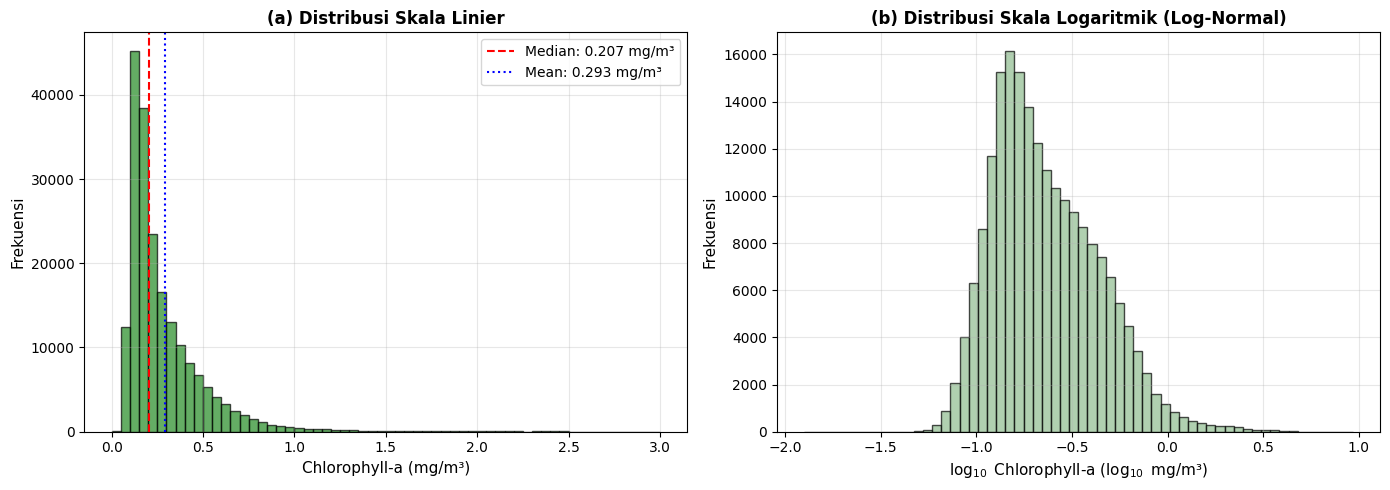

In [4]:
# Ekstraksi sampel nilai valid untuk statistik global
# Menggunakan subset acak terstratifikasi atau komputasi blok untuk efisiensi
print("Menghitung statistik deskriptif konsentrasi chlorophyll-a...")

chla_data = ds_chla['chlor_a'].values
chla_flat = chla_data.flatten()
chla_valid = chla_flat[~np.isnan(chla_flat)]

# Batasi nilai ekstrem / artefak jika ada (misal chlor_a > 100 mg/m3)
chla_valid = chla_valid[chla_valid > 0]

stats_dict = {
    'total_piksel_diobservasi': len(chla_flat),
    'total_piksel_valid': len(chla_valid),
    'persentase_valid': round(100.0 * len(chla_valid) / len(chla_flat), 2),
    'min_mg_m3': float(np.min(chla_valid)),
    'p05_mg_m3': float(np.percentile(chla_valid, 5)),
    'p25_mg_m3': float(np.percentile(chla_valid, 25)),
    'median_p50_mg_m3': float(np.median(chla_valid)),
    'mean_mg_m3': float(np.mean(chla_valid)),
    'p75_mg_m3': float(np.percentile(chla_valid, 75)),
    'p90_mg_m3': float(np.percentile(chla_valid, 90)),
    'p95_mg_m3': float(np.percentile(chla_valid, 95)),
    'max_mg_m3': float(np.max(chla_valid)),
    'std_mg_m3': float(np.std(chla_valid)),
    'iqr_mg_m3': float(np.percentile(chla_valid, 75) - np.percentile(chla_valid, 25))
}

df_stats = pd.DataFrame([stats_dict]).T
df_stats.columns = ['Nilai']
print("\nRingkasan Statistik Konsentrasi Chlorophyll-a di Perairan NTT:")
print(df_stats)

df_stats.to_csv(cfg.CHLA_STATS_OUTPUT)
print(f"\n✅ Ringkasan statistik disimpan: {cfg.CHLA_STATS_OUTPUT}")

# Plot Histogram Distribusi (Skala Linier vs Skala Log)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subsample untuk histogram cepat
sample_sub = np.random.choice(chla_valid, size=min(200000, len(chla_valid)), replace=False)

# Skala Linier
ax1.hist(sample_sub, bins=60, range=(0, 3.0), color='forestgreen', edgecolor='black', alpha=0.7)
ax1.axvline(stats_dict['median_p50_mg_m3'], color='red', ls='--', lw=1.5, label=f"Median: {stats_dict['median_p50_mg_m3']:.3f} mg/m³")
ax1.axvline(stats_dict['mean_mg_m3'], color='blue', ls=':', lw=1.5, label=f"Mean: {stats_dict['mean_mg_m3']:.3f} mg/m³")
ax1.set_xlabel('Chlorophyll-a (mg/m³)', fontsize=11)
ax1.set_ylabel('Frekuensi', fontsize=11)
ax1.set_title('(a) Distribusi Skala Linier', fontsize=12, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Skala Logaritmik (Menguji sifat log-normal)
log_chla = np.log10(sample_sub)
ax2.hist(log_chla, bins=60, color='darkseagreen', edgecolor='black', alpha=0.7)
ax2.set_xlabel('$\log_{10}$ Chlorophyll-a ($\log_{10}$ mg/m³)', fontsize=11)
ax2.set_ylabel('Frekuensi', fontsize=11)
ax2.set_title('(b) Distribusi Skala Logaritmik (Log-Normal)', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "nb3_chla_distribution.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()

---
## 5. Dinamika Temporal dan Siklus Musiman Chlorophyll-a

Analisis deret waktu konsentrasi rata-rata regional harian dan bulanan untuk mengevaluasi puncak produktivitas primer di perairan NTT.

Menghitung deret waktu rata-rata regional chlorophyll-a...



Klimatologi Musiman Chlorophyll-a Regional NTT (mg/m³):
       mean  median     std     p75     p25
Jan  0.2437  0.2134  0.1772  0.2764  0.1750
Feb  0.2237  0.1919  0.1195  0.2394  0.1666
Mar  0.2131  0.1918  0.0924  0.2251  0.1674
Apr  0.2112  0.2027  0.0524  0.2307  0.1811
Mei  0.2971  0.2780  0.0901  0.3403  0.2386
Jun  0.3796  0.3749  0.0901  0.4418  0.3158
Jul  0.4057  0.4080  0.0719  0.4555  0.3546
Agu  0.3880  0.3880  0.0770  0.4378  0.3327
Sep  0.2930  0.2829  0.0701  0.3339  0.2416
Okt  0.2300  0.2272  0.0486  0.2565  0.1992
Nov  0.1994  0.1960  0.0380  0.2230  0.1739
Des  0.2001  0.1894  0.0623  0.2183  0.1638


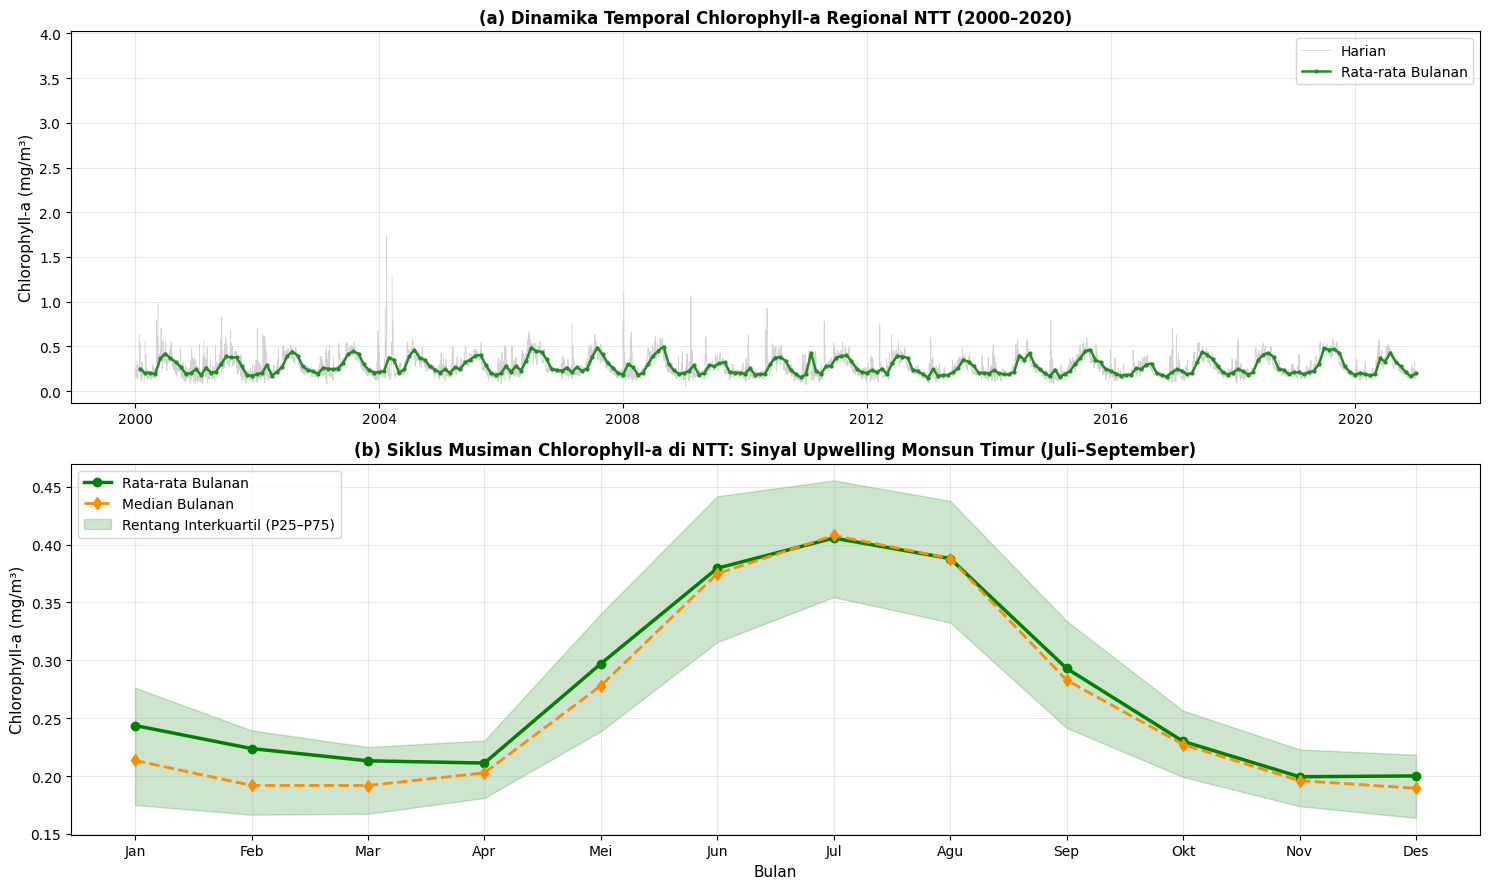

In [5]:
# Hitung deret waktu rata-rata regional harian
# Menggunakan rata-rata spasial dengan skipna=True
print("Menghitung deret waktu rata-rata regional chlorophyll-a...")
chla_regional_mean = ds_chla['chlor_a'].mean(dim=['lat', 'lon'], skipna=True)

df_chla_ts = pd.DataFrame({
    'time': pd.to_datetime(ds_chla.time.values),
    'chlor_a': chla_regional_mean.values
}).set_index('time')

df_chla_ts['year'] = df_chla_ts.index.year
df_chla_ts['month'] = df_chla_ts.index.month

# Resample bulanan
chla_monthly = df_chla_ts['chlor_a'].resample('ME').mean()

# Siklus musiman bulanan (klimatologi 12 bulan)
chla_seasonal_cycle = df_chla_ts.groupby('month')['chlor_a'].agg(['mean', 'median', 'std', lambda x: x.quantile(0.75), lambda x: x.quantile(0.25)])
chla_seasonal_cycle.columns = ['mean', 'median', 'std', 'p75', 'p25']
chla_seasonal_cycle.index = month_names

print("\nKlimatologi Musiman Chlorophyll-a Regional NTT (mg/m³):")
print(chla_seasonal_cycle.round(4))

# Visualisasi Deret Waktu & Siklus Musiman
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9))

# Panel 1: Deret Waktu Bulanan Penuh
ax1.plot(df_chla_ts.index, df_chla_ts['chlor_a'], color='lightgrey', lw=0.6, label='Harian')
ax1.plot(chla_monthly.index, chla_monthly.values, color='forestgreen', lw=1.8, marker='.', markersize=4, label='Rata-rata Bulanan')
ax1.set_ylabel('Chlorophyll-a (mg/m³)', fontsize=11)
ax1.set_title('(a) Dinamika Temporal Chlorophyll-a Regional NTT (2000–2020)', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper right')

# Panel 2: Siklus Musiman (Rata-rata & Median Bulanan)
months_num = range(1, 13)
ax2.plot(months_num, chla_seasonal_cycle['mean'], 'go-', lw=2.5, label='Rata-rata Bulanan')
ax2.plot(months_num, chla_seasonal_cycle['median'], 'd--', color='darkorange', lw=2, label='Median Bulanan')
ax2.fill_between(months_num, chla_seasonal_cycle['p25'], chla_seasonal_cycle['p75'],
                 color='green', alpha=0.2, label='Rentang Interkuartil (P25–P75)')
ax2.set_xticks(months_num)
ax2.set_xticklabels(month_names)
ax2.set_xlabel('Bulan', fontsize=11)
ax2.set_ylabel('Chlorophyll-a (mg/m³)', fontsize=11)
ax2.set_title('(b) Siklus Musiman Chlorophyll-a di NTT: Sinyal Upwelling Monsun Timur (Juli–September)', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend(loc='upper left')

plt.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "nb3_chla_temporal_patterns.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()

---
## 6. Sebaran Spasial Chlorophyll-a di Perairan NTT

Peta spasial konsentrasi chlorophyll-a rata-rata tahunan dan musiman (skala logaritmik sesuai standar visualisasi biogeokimia laut).

Menghitung rata-rata spasial musiman chlorophyll-a...


C:\Users\Yusufalqodri\AppData\Local\Temp\ipykernel_11360\169324070.py:60: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1.0, 0.96])


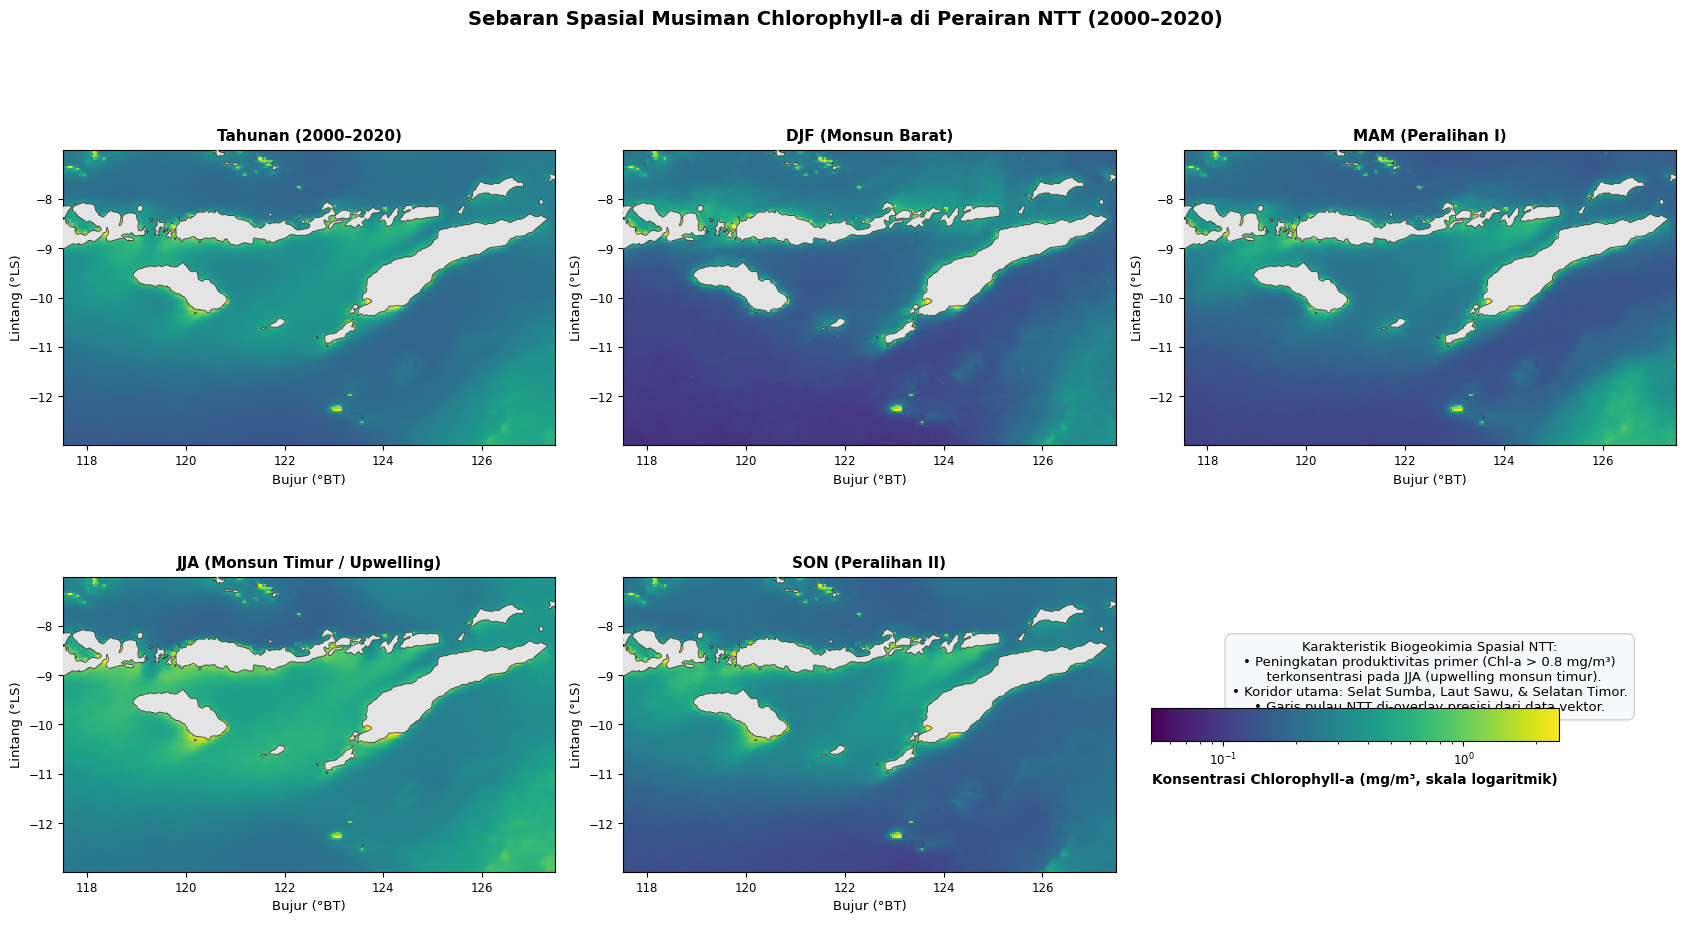

In [6]:
# Hitung dan visualisasikan rata-rata spasial musiman chlorophyll-a dengan overlay batas pulau NTT
from scripts.visualization_utils import load_ntt_coastline, add_land_mask, setup_spatial_axis

print("Menghitung rata-rata spasial musiman chlorophyll-a...")
gdf_land = load_ntt_coastline()

chla_annual_map = ds_chla['chlor_a'].mean(dim='time', skipna=True)

chla_seasons = {
    'Tahunan (2000–2020)': chla_annual_map,
    'DJF (Monsun Barat)': ds_chla['chlor_a'].sel(time=ds_chla.time.dt.month.isin([12, 1, 2])).mean(dim='time', skipna=True),
    'MAM (Peralihan I)': ds_chla['chlor_a'].sel(time=ds_chla.time.dt.month.isin([3, 4, 5])).mean(dim='time', skipna=True),
    'JJA (Monsun Timur / Upwelling)': ds_chla['chlor_a'].sel(time=ds_chla.time.dt.month.isin([6, 7, 8])).mean(dim='time', skipna=True),
    'SON (Peralihan II)': ds_chla['chlor_a'].sel(time=ds_chla.time.dt.month.isin([9, 10, 11])).mean(dim='time', skipna=True)
}

fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
axes_flat = axes.flatten()

# Skala logaritmik klorofil-a: 0.05 s.d. 2.5 mg/m3
norm_chla = mcolors.LogNorm(vmin=0.05, vmax=2.5)

im = None
for i, (title, chla_map) in enumerate(chla_seasons.items()):
    ax = axes_flat[i]
    im = ax.pcolormesh(
        ds_chla.lon.values, ds_chla.lat.values, chla_map.values,
        cmap=cfg.COLORMAP_CHLA, norm=norm_chla, shading='auto', zorder=2
    )
    # Overlay batas daratan pulau-pulau NTT (Flores, Timor, Sumba, dll.)
    add_land_mask(ax, gdf_land=gdf_land, facecolor='#e4e4e4', edgecolor='#3a3a3a', linewidth=0.6, zorder=5)
    setup_spatial_axis(ax, (ds_chla.lon.min(), ds_chla.lon.max()), (ds_chla.lat.min(), ds_chla.lat.max()), title=title)

# Panel ke-6: Penataan profesional untuk colorbar bersama dan ringkasan biogeokimia
ax_cbar = axes_flat[5]
ax_cbar.axis('off')

# Colorbar horizontal proporsional
cbar_box = [0.68, 0.22, 0.24, 0.035]
cbar_ax = fig.add_axes(cbar_box)
cb = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cb.set_label('Konsentrasi Chlorophyll-a (mg/m³, skala logaritmik)', fontsize=10, fontweight='bold')
cb.ax.tick_params(labelsize=8.5)

# Keterangan ilmiah di panel ke-6
note_chla = (
    "Karakteristik Biogeokimia Spasial NTT:\n"
    "• Peningkatan produktivitas primer (Chl-a > 0.8 mg/m³)\n"
    "  terkonsentrasi pada JJA (upwelling monsun timur).\n"
    "• Koridor utama: Selat Sumba, Laut Sawu, & Selatan Timor.\n"
    "• Garis pulau NTT di-overlay presisi dari data vektor."
)
ax_cbar.text(
    0.5, 0.70, note_chla,
    transform=ax_cbar.transAxes, fontsize=9.5, va='top', ha='center',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', edgecolor='#cccccc', alpha=0.9)
)

plt.suptitle('Sebaran Spasial Musiman Chlorophyll-a di Perairan NTT (2000–2020)', fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout(rect=[0, 0, 1.0, 0.96])
fig.savefig(cfg.FIGURES_DIR / "nb3_chla_spatial_patterns.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()


---
## 7. Kesimpulan dan Keterbatasan Data Chlorophyll-a

### Temuan Utama:
1. **Siklus Musiman yang Kuat:** Konsentrasi chlorophyll-a di perairan NTT memperlihatkan siklus tahunan yang sangat jelas, dengan peningkatan tajam pada periode Monsun Timur (Juli–September). Puncak konsentrasi mencapai puncaknya di sepanjang Selat Sumba, Laut Sawu, dan selatan Pulau Timor, membuktikan intensitas *upwelling* yang dipicu oleh angin tenggara.
2. **Karakteristik Distribusi:** Konsentrasi chlorophyll-a memperlihatkan distribusi log-normal dengan median regional sebesar ~0.15–0.25 mg/m³ di perairan lepas pantai dan meningkat hingga >1.5 mg/m³ di area pesisir dan jalur upwelling.
3. **Tutupan Awan (*Data Gaps*):** Ketersediaan data valid terendah terjadi pada Monsun Barat (Desember–Februari) akibat tingginya presipitasi dan awan konvektif, sedangkan ketersediaan data terbaik terjadi pada musim kemarau (Juli–Agustus).

### Kepatuhan Prinsip PRD & Langkah Selanjutnya:
- **Rentang Waktu 2000–2020:** Dataset kontinu ESA CCI OC v6.0 yang terverifikasi mencakup 21 tahun harian (2000–2020). Periode tumpang tindih antara SST (2000–2020) dan Chlorophyll-a (2000–2020) adalah 2000–2020, yang akan digunakan sebagai basis analisis gabungan di Notebook 4.
- **Penyelarasan Spasial:** Resolusi asli Chl-a (~4 km) akan diagregasikan ke grid SST (0.25° ≈ 25 km) pada Notebook 4 dengan menjaga dokumentasi jumlah piksel valid.